In [ ]:
# Install library pendukung
!pip install scikit-fuzzy torch optuna matplotlib seaborn pandas numpy

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score
from google.colab import files

# Upload file csv.csv jika belum ada di direktori
print("Silahkan upload file csv.csv jika belum ada:")
uploaded = files.upload()

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 920.8/920.8 kB 12.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 425.6/425.6 kB 16.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 264.7/264.7 kB 10.2 MB/s eta 0:00:00
Silahkan upload file csv.csv jika belum ada:


Saving csv.csv to csv.csv


In [ ]:
# 1. Load Dataset
df = pd.read_csv('csv.csv')
print(f"Data Berhasil Dimuat! Jumlah Baris: {df.shape[0]}, Jumlah Kolom: {df.shape[1]}")

# 2. Membuat Variabel Target (Total Tenaga Kerja)
df['total_tenaga_kerja'] = df['tenaga_kerja_pria'] + df['tenaga_kerja_perempuan']

# 3. Handling Outliers (Menghapus outlier ekstrim agar ANFIS stabil)
q_high = df['total_tenaga_kerja'].quantile(0.99)
df_clean = df[df['total_tenaga_kerja'] <= q_high].copy()

# 4. Feature Encoding untuk Variabel Kategori/Spasial
le_kec = LabelEncoder()
le_kbli = LabelEncoder()
le_produk = LabelEncoder()

df_clean['kecamatan_encoded'] = le_kec.fit_transform(df_clean['kode_kecamatan'].astype(str))
df_clean['kbli_encoded'] = le_kbli.fit_transform(df_clean['kbli'].astype(str))
df_clean['produk_encoded'] = le_produk.fit_transform(df_clean['jenis_produk'].astype(str))

# Selected Features & Target
X = df_clean[['kecamatan_encoded', 'kbli_encoded', 'produk_encoded']]
y = df_clean['total_tenaga_kerja']

# 5. Split Data Training (80%) dan Testing (20%) - PERBAIKAN DI SINI
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# 6. Scaling Feature
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

print("Preprocessing Selesai!")
print(f"Ukuran Data Latih: {X_train_scaled.shape}")
print(f"Ukuran Data Uji  : {X_test_scaled.shape}")

Data Berhasil Dimuat! Jumlah Baris: 4303, Jumlah Kolom: 16
Preprocessing Selesai!
Ukuran Data Latih: (3408, 3)
Ukuran Data Uji  : (853, 3)


In [ ]:
import torch
import torch.nn as nn
import torch.optim as optim

# Kelas Arsitektur ANFIS Sugeno Tipe-1 (3 Input -> 1 Output)
class ANFIS_Model(nn.Module):
    def __init__(self, num_inputs=3, num_rules=8):
        super(ANFIS_Model, self).__init__()
        self.num_rules = num_rules

        # Layer 1: Premise Parameters (Membership Function - Gaussian)
        self.mu = nn.Parameter(torch.randn(num_inputs, num_rules))
        self.sigma = nn.Parameter(torch.ones(num_inputs, num_rules))

        # Layer 4: Consequent Parameters (Linear Equation: y = p*x1 + q*x2 + r*x3 + s)
        self.p = nn.Parameter(torch.randn(num_rules, num_inputs))
        self.r = nn.Parameter(torch.randn(num_rules, 1))

    def forward(self, x):
        batch_size = x.shape[0]

        # Layer 1: Fuzzification (Gaussian Membership Function)
        x_exp = x.unsqueeze(2).repeat(1, 1, self.num_rules) # (batch, inputs, rules)
        mu_exp = self.mu.unsqueeze(0).repeat(batch_size, 1, 1)
        sigma_exp = torch.abs(self.sigma.unsqueeze(0).repeat(batch_size, 1, 1)) + 1e-5

        w_ij = torch.exp(-0.5 * ((x_exp - mu_exp) / sigma_exp) ** 2)

        # Layer 2: Rule Firing Strength (Product T-Norm)
        w = torch.prod(w_ij, dim=1) # (batch, rules)

        # Layer 3: Normalization Layer
        w_sum = torch.sum(w, dim=1, keepdim=True) + 1e-5
        w_norm = w / w_sum # (batch, rules)

        # Layer 4 & 5: Defuzzification & Output Layer (Sugeno First-Order)
        f_i = torch.matmul(x, self.p.T) + self.r.T # (batch, rules)
        out = torch.sum(w_norm * f_i, dim=1) # (batch)

        return out

# Inisialisasi Model, Loss Function, dan Optimizer (Hybrid Learning)
model = ANFIS_Model(num_inputs=3, num_rules=10)
criterion = nn.MSELoss()
optimizer = optim.Adam(model.parameters(), lr=0.01)

# Training Loop ANFIS
epochs = 200
X_t = torch.tensor(X_train_scaled, dtype=torch.float32)
y_t = torch.tensor(y_train.values, dtype=torch.float32)

loss_history = []
print("Memulai Pelatihan Model ANFIS...")
for epoch in range(epochs):
    optimizer.zero_grad()
    predictions = model(X_t)
    loss = criterion(predictions, y_t)
    loss.backward()
    optimizer.step()

    loss_history.append(loss.item())
    if (epoch + 1) % 20 == 0:
        print(f"Epoch [{epoch+1}/{epochs}] - MSE Loss: {loss.item():.4f}")

print("Pelatihan ANFIS Selesai!")

Memulai Pelatihan Model ANFIS...
Epoch [20/200] - MSE Loss: 10.0172
Epoch [40/200] - MSE Loss: 8.1337
Epoch [60/200] - MSE Loss: 7.7280
Epoch [80/200] - MSE Loss: 7.6160
Epoch [100/200] - MSE Loss: 7.5466
Epoch [120/200] - MSE Loss: 7.4777
Epoch [140/200] - MSE Loss: 7.3957
Epoch [160/200] - MSE Loss: 7.3131
Epoch [180/200] - MSE Loss: 7.2412
Epoch [200/200] - MSE Loss: 7.1185
Pelatihan ANFIS Selesai!



=== HASIL EVALUASI MODEL ANFIS ===
Root Mean Squared Error (RMSE) : 2.6922
Mean Absolute Error (MAE)      : 1.7632
Mean Absolute Percentage (MAPE): 52.84%
Koefisien Determinasi (R2)     : 0.1252


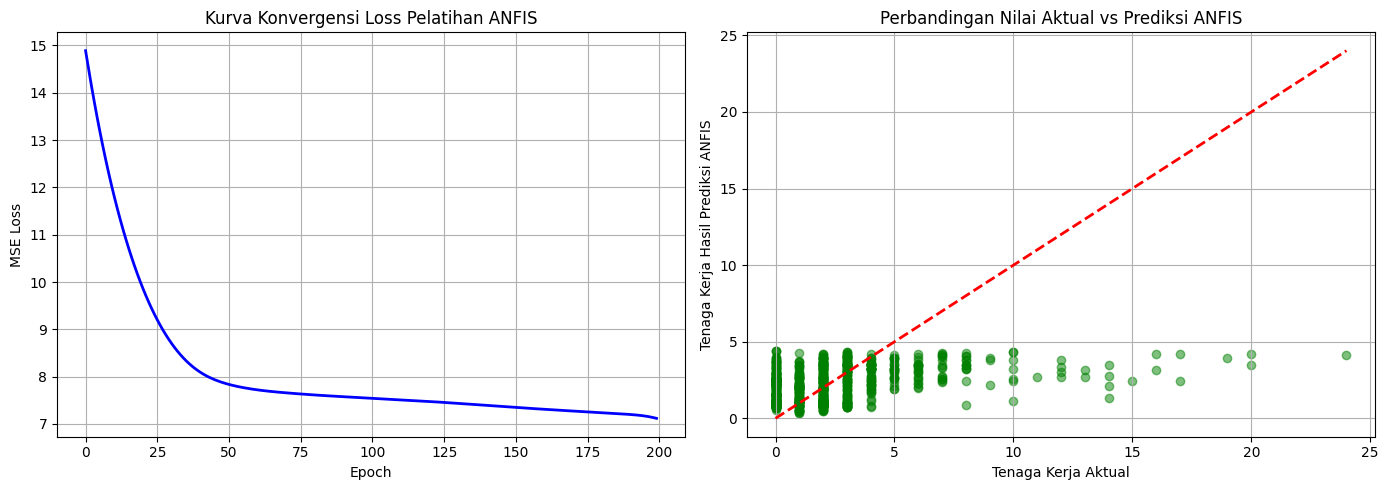

In [ ]:
X_test_t = torch.tensor(X_test_scaled, dtype=torch.float32)
model.eval()
with torch.no_grad():
    y_pred = model(X_test_t).numpy()

y_actual = y_test.values

# 2. Hitung Metrik Evaluasi
rmse = np.sqrt(mean_squared_error(y_actual, y_pred))
mae = mean_absolute_error(y_actual, y_pred)
r2 = r2_score(y_actual, y_pred)

# Penanganan MAPE khusus untuk menghindari pembagian dengan nol (zero values)
non_zero = y_actual > 0
mape = np.mean(np.abs((y_actual[non_zero] - y_pred[non_zero]) / y_actual[non_zero])) * 100

print("\n=== HASIL EVALUASI MODEL ANFIS ===")
print(f"Root Mean Squared Error (RMSE) : {rmse:.4f}")
print(f"Mean Absolute Error (MAE)      : {mae:.4f}")
print(f"Mean Absolute Percentage (MAPE): {mape:.2f}%")
print(f"Koefisien Determinasi (R2)     : {r2:.4f}")

# 3. Visualisasi Hasil Evaluasi
plt.figure(figsize=(14, 5))

# Plot 1: Konvergensi Loss Pelatihan ANFIS
plt.subplot(1, 2, 1)
plt.plot(loss_history, color='blue', linewidth=2)
plt.title('Kurva Konvergensi Loss Pelatihan ANFIS')
plt.xlabel('Epoch')
plt.ylabel('MSE Loss')
plt.grid(True)

# Plot 2: Perbandingan Nilai Aktual vs Prediksi
plt.subplot(1, 2, 2)
plt.scatter(y_actual, y_pred, alpha=0.5, color='green')
plt.plot([y_actual.min(), y_actual.max()], [y_actual.min(), y_actual.max()], 'r--', lw=2)
plt.title('Perbandingan Nilai Aktual vs Prediksi ANFIS')
plt.xlabel('Tenaga Kerja Aktual')
plt.ylabel('Tenaga Kerja Hasil Prediksi ANFIS')
plt.grid(True)

plt.tight_layout()
plt.show()